# ECS 174 Computer Vision
## Homework 1
### Adam Hetherwick
October 2026

This code is meant to be run on Google Colab for accurate file loading and GPU usage.

Instructions:  For all the following sections, train the model for 50 epochs and plot the curve for loss, training accuracy,
and test accuracy evaluated every epoch. In scenarios where training takes so long, you may decrease total
number of epochs.

### Problem 1

Run the tutorial code out of the box and make sure you get reasonable results. You will report these results in Section 4, so no report needed here.
https://pytorch.org/tutorials/_downloads/cifar10_tutorial.py

In [1]:
# Package import

import torch
import torchvision
import torchvision.transforms as transforms

In [4]:
!pip install -q datasets

In [6]:
transform = transforms.Compose(
    [transforms.ToTensor(),                                     # .ToTensor() rearranges dimension to channels x height x width and scale to [0, 1]
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])   # .Normalize() scales to [-1, 1]

In [ ]:
from datasets import load_dataset
from torch.utils.data import Dataset

In [51]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=4,
                                         shuffle=False, num_workers=2)

100%|██████████| 170M/170M [18:29<00:00, 154kB/s]


In [52]:
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

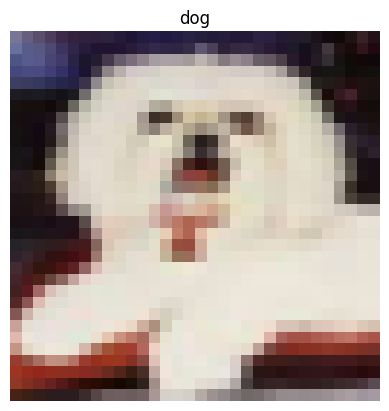

In [44]:
# Visualize images

import matplotlib.pyplot as plt
import numpy as np
import random

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

i = random.randint(0, len(trainset) - 1)
img, label = trainset[i]
imshow(img)
plt.title(classes[label])
plt.axis('off')
plt.show()

In [45]:
import torch.nn as nn
import torch.nn.functional as F

In [53]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [54]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net().to(device)

In [55]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [59]:
losses = []

for epoch in range(50):
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)   # <-- this line

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    losses.append(epoch_loss)
    print(f'epoch: {epoch + 1}/50, loss: {epoch_loss:.4f}')

epoch: 1/50, loss: 1.6911
epoch: 2/50, loss: 1.3421
epoch: 3/50, loss: 1.2068
epoch: 4/50, loss: 1.1210
epoch: 5/50, loss: 1.0472
epoch: 6/50, loss: 0.9933
epoch: 7/50, loss: 0.9461
epoch: 8/50, loss: 0.9059
epoch: 9/50, loss: 0.8686
epoch: 10/50, loss: 0.8401
epoch: 11/50, loss: 0.8122
epoch: 12/50, loss: 0.7892
epoch: 13/50, loss: 0.7649
epoch: 14/50, loss: 0.7482
epoch: 15/50, loss: 0.7323
epoch: 16/50, loss: 0.7189
epoch: 17/50, loss: 0.7007
epoch: 18/50, loss: 0.6900
epoch: 19/50, loss: 0.6888
epoch: 20/50, loss: 0.6679
epoch: 21/50, loss: 0.6626
epoch: 22/50, loss: 0.6563


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fea030d8a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1673, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
  File "/usr/lib/python3.13/multiprocessing/popen_fork.py", line 41, in wait
    if not wait([self.sentinel], timeout):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 1174, in wait
    ready = selector.select(timeout)
  File "/usr/lib/python3.13/selectors.py", line 398, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 
Exception ignored in sys.unraisablehook: <built-in function unraisablehook>
Traceback (most recent 

KeyboardInterrupt: 

In [ ]:
plt.plot(range(1, 51), losses)
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.show()

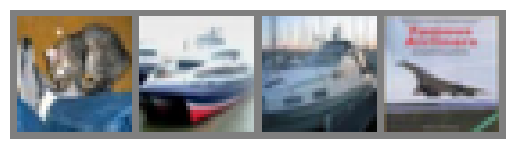

GroundTruth:    cat  ship  ship plane
Predicted:    cat   car   car  ship


In [36]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
plt.axis('off')
plt.show()
print('GroundTruth: ', ' '.join('%5s' % classes[labels[j]] for j in range(4)))

# print predictions
outputs = net(images)
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join('%5s' % classes[predicted[j]]
                              for j in range(4)))

In [37]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

Accuracy of the network on the 10000 test images: 53 %


### Problem 2

Change the code to have only a single fully connected layer. The model will have a single layer that
connects the input to the output. What is the number of parameters? In PyTorch, ”nn.Linear” can
be used for fully connected layer.

### Problem 3

Change the code to have multiple fully connected layers. Try having a layer from input to 110 neurons
and then a layer to 74 neurons, and finally a layer to 10 neurons, one for each category. What happens
if you do not use ReLU? Describe why.

### Problem 4

Change the code by adding two convolutional layers along with maxpooling layers before the fully
connected layers. This will be similar to the example in the tutorial. Use this model for the following
sections.

### Problem 5

Try multiple batch sizes to see the effect and describe the findings. Please use batch size of 1, 4, and
1000. If 1000 does not fit into the memory of your machine, please feel free to reduce it to the largest
possible number.

### Problem 6

Try multiple learning rates to see the effect and describe the findings. Please use learning rates of 10,
0.1, 0.01, and 0.001.

### Problem 7

Please add some data augmentation to avoid overfitting. Note that you need to do this only for the
trainnig and not the testing. You may use line 244-260 from Imagenet sample code:

https://github.com/pytorch/examples/blob/master/imagenet/main.py